# Lecture 10: Balancing a SAM with cross entropy

The last lecture turns from the model to its data. A SAM assembled from several sources does not balance, and a model cannot be calibrated on it until every account's income equals its spending. The lecture balances a perturbed copy of the previous notebook's SAM by cross entropy, which finds the balanced SAM closest to the unbalanced one in the sense of information theory. There is no correction video, so the target is the solution the lecture's GAMS program prints.

:::{admonition} Watch the lecture
:class: tip

- 📺 Lecture: [Balancing a SAM: the cross-entropy technique](https://www.youtube.com/watch?v=KBW5JOKCHzs)
- 🎓 Full course playlist: [Antoine Bouet's CGE lectures](https://www.youtube.com/playlist?list=PLfV47vAW_jrc57x1O36Pz9vol86f0YUXW)
:::

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import cge_modeling as cm

## The prior

The unbalanced SAM, called the prior, has the eleven accounts of the previous notebook. Each sector combines an activity and its commodity, and the government cell under each sector adds the commodity tax and the value added tax.

In [2]:
sectors = ["Agr", "Ind", "Serv"]
factors = ["Land", "LD", "SKLD", "KD"]
accounts = [*factors, "Hld", "Gvt", *sectors, "Inv", "RoW"]

prior = pd.DataFrame(0.0, index=accounts, columns=accounts)
prior.loc["Land", sectors] = [690.0, 0.0, 0.0]
prior.loc["LD", sectors] = [480.0, 1530.0, 4060.0]
prior.loc["SKLD", sectors] = [200.0, 870.0, 280.0]
prior.loc["KD", sectors] = [50.0, 900.0, 250.0]
prior.loc["Hld", [*factors, "Gvt", "RoW"]] = [600.0, 6070.0, 1400.0, 1200.0, 100.0, 523.0]
prior.loc["Gvt", ["Hld", *sectors, "RoW"]] = [1400.0, 215.0, 1505.0, 370.0, 58.0]
prior.loc[sectors, "Hld"] = [1750.0, 1200.0, 3400.0]
prior.loc[sectors, "Gvt"] = [500.0, 1030.0, 2785.0]
prior.loc[sectors, "Inv"] = [200.0, 745.0, 100.0]
prior.loc[sectors, "RoW"] = [331.0, 37.0, 1900.0]
prior.loc[sectors, sectors] = [[1120.0, 930.0, 1150.0],
                               [2200.0, 3120.0, 3398.0],
                               [870.0, 2250.0, 1100.0]]
prior.loc["Inv", ["Hld", "Gvt", "RoW"]] = [2180.0, -800.0, -325.0]
prior.loc["RoW", sectors] = [150.0, 440.0, 95.0]

Income and spending disagree for every account except unskilled labor and capital. The rest of the world is furthest off, because the prior records services exports of 1900.

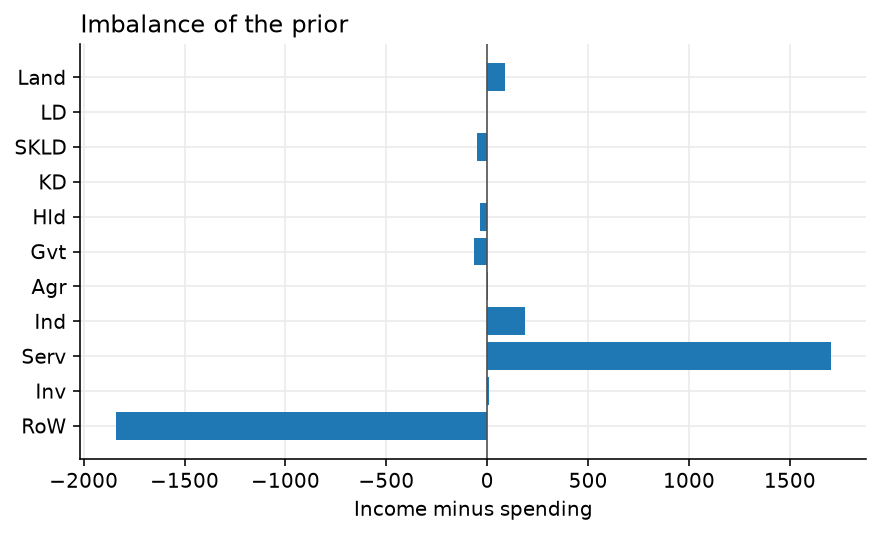

In [3]:
gap = prior.sum(axis=1) - prior.sum(axis=0)

fig, ax = plt.subplots(figsize=(6, 3.6),
                       dpi=144,
                       layout="constrained")
ax.barh(y=gap.index,
        width=gap,
        color="C0")
ax.axvline(x=0.0,
           color="0.3",
           linewidth=0.8)
ax.invert_yaxis()
ax.set(xlabel="Income minus spending")
ax.set_title("Imbalance of the prior",
             loc="left")
ax.grid(color="0.92")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Cross entropy

The lecture divides every cell by the grand total $T$ of the prior to get coefficients $a^0_{ij}$. The logarithm needs positive coefficients, so a negative cell moves to the transposed position: $-a^0_{ij}$ goes into cell $(j, i)$ and cell $(i, j)$ becomes zero. A negative payment from $j$ to $i$ is the same flow as a positive payment from $i$ to $j$, so the move leaves every account's income minus spending unchanged. The balanced coefficients $a^1_{ij}$ solve

$$
\begin{aligned}
\min_{a^1} \quad & \sum_i \sum_j a^1_{ij} \ln \frac{a^1_{ij}}{a^0_{ij}} \\
\text{subject to} \quad & \sum_j a^1_{ij} = \sum_j a^1_{ji} \quad \text{for every account } i \\
& \sum_i \sum_j a^1_{ij} = 1
\end{aligned}
$$

and only cells that are nonzero in the prior enter the problem, so the balanced SAM keeps the prior's structure. The balanced SAM is $T \cdot a^1_{ij}$, with the negative cells moved back.

`cm.SymbolicSAM` solves a variant of this problem. It keeps negative cells in place with their sign fixed and measures each cell by its magnitude. Its default objective is the generalized KL divergence $\sum_k |x_k| \ln \frac{|x_k|}{|z_k|} - |x_k| + |z_k|$ between the estimate $x$ and the prior $z$, with no constraint on the total.

In [4]:
tolerances = {"solver": "CLARABEL",
              "tol_gap_abs": 1e-10,
              "tol_gap_rel": 1e-10,
              "tol_feas": 1e-10}
course_totals = pd.Series([622.1, 5989.4, 1343.1, 1173.2, 9531.6, 3424.6, 5749.8, 11407.6, 10813.3, 961.1, 1112.5],
                          index=accounts)

kl_estimate = cm.SymbolicSAM(prior).fit()

Both objectives balance the SAM in the same way: each positive cell becomes $z_{ij} \cdot \frac{d_j}{d_i}$ and each negative cell $z_{ij} \cdot \frac{d_i}{d_j}$, for one scale $d_i$ per account. The accounting identity fixes the scales up to a common factor, so the two problems can differ only in the overall level. The course's constraint $\sum a^1_{ij} = 1$ sets the total magnitude of the balanced cells to $T = 54607$, the signed total of the prior. The generalized KL divergence leaves the level free.

The signs of the cells are fixed, so the total magnitude is linear in the cells: it is the sum of the cells minus twice the negative ones. Adding it as a constraint reproduces the course's SAM.

In [5]:
course_sam = cm.SymbolicSAM(prior)
negative_cells = course_sam.sel(row="Inv", col="Gvt") + course_sam.sel(row="Inv", col="RoW")
course_sam.subject_to(total=course_sam.sum() - 2 * negative_cells == prior.to_numpy().sum())

course_estimate = course_sam.fit(**tolerances)

Without the constraint, every account total is 3.2% above the course's. With it, every total matches the lecture's printed value to within 0.1.

In [6]:
ratios = pd.DataFrame({"generalized KL": kl_estimate.sam.sum(axis=1) / course_totals,
                       "generalized KL, course total": course_estimate.sam.sum(axis=1) / course_totals})

ratios.agg(["min", "max"]).T.rename(columns={"min": "smallest ratio to course", "max": "largest ratio to course"}).round(4)

,smallest ratio to course,largest ratio to course
generalized KL,1.0321,1.0322
"generalized KL, course total",1.0000,1.0000


The largest adjustments are in the rest of the world, the account furthest from balance. Services exports fall from 1900 to 1057, imports of each good rise by about 60%, and remittances to the household fall by about 40%. Services sales at home fall too, because every cell in the services row shares the services account's scale.

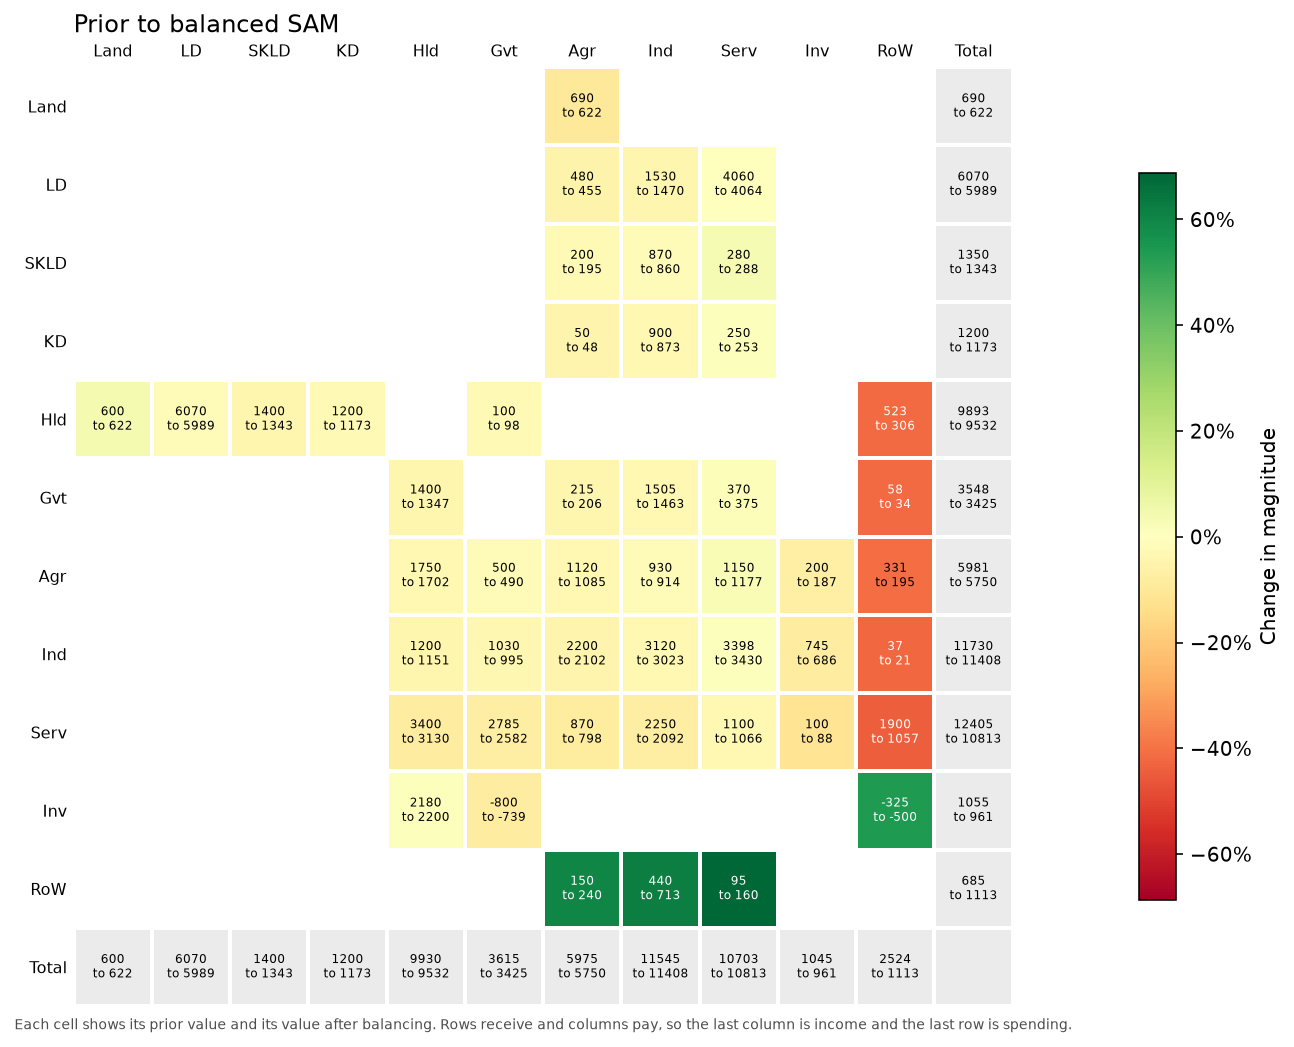

In [7]:
balanced = course_estimate.sam
relative_change = (balanced.abs() / prior.abs() - 1.0).where(prior != 0.0)
largest_change = np.nanmax(np.abs(relative_change.to_numpy()))
n_accounts = len(accounts)

# The SAM fills the top left of a grid with one extra row and column for the totals.
grid = np.full((n_accounts + 1, n_accounts + 1), np.nan)
grid[:n_accounts, :n_accounts] = relative_change.to_numpy()

fig, ax = plt.subplots(figsize=(9, 8.5),
                       dpi=144,
                       layout="constrained")
image = ax.imshow(grid,
                  cmap="RdYlGn",
                  vmin=-largest_change,
                  vmax=largest_change)
for position in range(n_accounts + 1):
    ax.add_patch(plt.Rectangle(xy=(n_accounts - 0.5, position - 0.5),
                               width=1.0,
                               height=1.0,
                               facecolor="0.92"))
    ax.add_patch(plt.Rectangle(xy=(position - 0.5, n_accounts - 0.5),
                               width=1.0,
                               height=1.0,
                               facecolor="0.92"))

for i, row in enumerate(accounts):
    for j, column in enumerate(accounts):
        if prior.loc[row, column] != 0.0:
            # White text keeps the label readable on the darkest cells.
            strong = abs(relative_change.loc[row, column]) > 0.6 * largest_change
            ax.text(x=j,
                    y=i,
                    s=f"{prior.loc[row, column]:g}\nto {balanced.loc[row, column]:.0f}",
                    ha="center",
                    va="center",
                    fontsize=6,
                    color="white" if strong else "black")
for position, account in enumerate(accounts):
    ax.text(x=n_accounts,
            y=position,
            s=f"{prior.loc[account].sum():g}\nto {balanced.loc[account].sum():.0f}",
            ha="center",
            va="center",
            fontsize=6)
    ax.text(x=position,
            y=n_accounts,
            s=f"{prior[account].sum():g}\nto {balanced[account].sum():.0f}",
            ha="center",
            va="center",
            fontsize=6)

ax.set_xticks(ticks=range(n_accounts + 1), labels=[*accounts, "Total"])
ax.set_yticks(ticks=range(n_accounts + 1), labels=[*accounts, "Total"])
ax.xaxis.tick_top()
ax.set_xticks(ticks=np.arange(n_accounts + 2) - 0.5, minor=True)
ax.set_yticks(ticks=np.arange(n_accounts + 2) - 0.5, minor=True)
ax.tick_params(which="both", length=0, labelsize=8)
ax.grid(which="minor", color="white", linewidth=2)
ax.spines[:].set_visible(False)
fig.colorbar(image,
             ax=ax,
             shrink=0.6,
             format="{x:.0%}",
             label="Change in magnitude")
ax.set_title("Prior to balanced SAM",
             loc="left")
ax.annotate(text="Each cell shows its prior value and its value after balancing. "
                 "Rows receive and columns pay, so the last column is income and the last row is spending.",
            xy=(0.5, 0.0),
            xycoords="axes fraction",
            xytext=(0, -6),
            textcoords="offset points",
            ha="center",
            va="top",
            fontsize=7,
            color="0.3")
plt.show()

## Interpretation and extension

The prior is the previous notebook's SAM with twenty cells perturbed, so the true SAM is known and the balanced SAM can be scored against it. The largest perturbation is services exports, 1900 against a true value of 100. The others are all below 100.

In [8]:
truth = pd.DataFrame(0.0, index=accounts, columns=accounts)
truth.loc["Land", sectors] = [600.0, 0.0, 0.0]
truth.loc["LD", sectors] = [450.0, 1560.0, 4060.0]
truth.loc["SKLD", sectors] = [200.0, 900.0, 300.0]
truth.loc["KD", sectors] = [50.0, 900.0, 250.0]
truth.loc["Hld", [*factors, "Gvt", "RoW"]] = [600.0, 6070.0, 1400.0, 1200.0, 100.0, 500.0]
truth.loc["Gvt", ["Hld", *sectors, "RoW"]] = [1400.0, 215.0, 1505.0, 370.0, 50.0]
truth.loc[sectors, "Hld"] = [1700.0, 1200.0, 3400.0]
truth.loc[sectors, "Gvt"] = [450.0, 1000.0, 2790.0]
truth.loc[sectors, "Inv"] = [200.0, 745.0, 100.0]
truth.loc[sectors, "RoW"] = [315.0, 30.0, 100.0]
truth.loc[sectors, sectors] = [[1120.0, 930.0, 1100.0],
                               [2200.0, 3120.0, 3300.0],
                               [830.0, 2250.0, 1100.0]]
truth.loc["Inv", ["Hld", "Gvt", "RoW"]] = [2170.0, -800.0, -325.0]
truth.loc["RoW", sectors] = [150.0, 430.0, 90.0]

Under cross entropy every cell of an account moves with the account's scale, so fixing the one bad cell moves the whole rest of the world account. The lecture argues that cross entropy can take in any new information. Customs data would supply total exports, 445 in the true SAM, as one more constraint. Least squares, with each cell's standard error set to its prior magnitude, has no account scales, so it can move one cell without moving the rest of its account. It gets the same export constraint.

In [9]:
customs_exports = truth.loc[sectors, "RoW"].sum()

entropy_sam = cm.SymbolicSAM(prior)
entropy_negative_cells = entropy_sam.sel(row="Inv", col="Gvt") + entropy_sam.sel(row="Inv", col="RoW")
entropy_sam.subject_to(total=entropy_sam.sum() - 2 * entropy_negative_cells == prior.to_numpy().sum(),
                       exports=entropy_sam.sel(row=sectors, col="RoW").sum() == customs_exports)

squares_sam = cm.SymbolicSAM(prior)
squares_sam.subject_to(exports=squares_sam.sel(row=sectors, col="RoW").sum() == customs_exports)

estimates = {"prior": prior,
             "cross entropy": course_estimate.sam,
             "cross entropy, export total": entropy_sam.fit(objective=cm.KL(), **tolerances).sam,
             "least squares, export total": squares_sam.fit(objective=cm.LeastSquares(), **tolerances).sam}

In [10]:
nonzero = truth.stack() != 0.0
perturbed = (prior != truth).stack()[nonzero]
errors = pd.DataFrame({name: (sam - truth).abs().stack()[nonzero] for name, sam in estimates.items()})

error_table = errors.groupby(perturbed.map({True: "perturbed cells", False: "other cells"})).sum().T

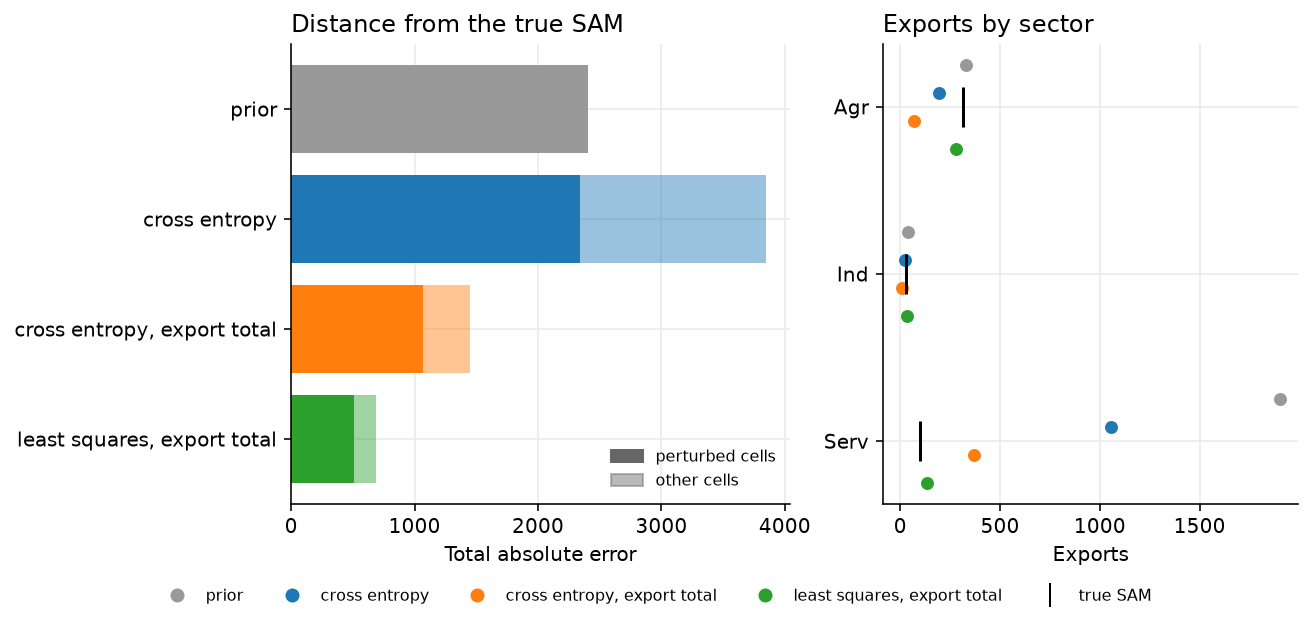

In [11]:
colors = {"prior": "0.6",
          "cross entropy": "C0",
          "cross entropy, export total": "C1",
          "least squares, export total": "C2"}
positions = np.arange(len(estimates))[::-1]
exports = pd.DataFrame({name: sam.loc[sectors, "RoW"] for name, sam in estimates.items()})

fig, (error_ax, export_ax) = plt.subplots(ncols=2,
                                          figsize=(9, 4.2),
                                          dpi=144,
                                          layout="constrained",
                                          gridspec_kw={"width_ratios": [1.2, 1]})

error_ax.barh(y=positions,
              width=error_table["perturbed cells"],
              color=list(colors.values()))
error_ax.barh(y=positions,
              width=error_table["other cells"],
              left=error_table["perturbed cells"],
              color=list(colors.values()),
              alpha=0.45)
error_ax.set(yticks=positions,
             xlabel="Total absolute error")
error_ax.set_yticklabels(estimates.keys())
error_ax.set_title("Distance from the true SAM",
                   loc="left")
error_ax.legend(handles=[Patch(color="0.4"), Patch(color="0.4", alpha=0.45)],
                labels=["perturbed cells", "other cells"],
                frameon=False,
                fontsize=8,
                loc="lower right")

sector_positions = np.arange(len(sectors))[::-1]
offsets = np.linspace(0.25, -0.25, len(estimates))
for offset, (name, color) in zip(offsets, colors.items()):
    export_ax.scatter(x=exports[name],
                      y=sector_positions + offset,
                      color=color,
                      s=30,
                      zorder=2)
export_ax.scatter(x=truth.loc[sectors, "RoW"],
                  y=sector_positions,
                  marker="|",
                  color="black",
                  s=400,
                  zorder=3)
export_ax.set(yticks=sector_positions,
              xlabel="Exports")
export_ax.set_yticklabels(sectors)
export_ax.set_title("Exports by sector",
                    loc="left")

for ax in (error_ax, export_ax):
    ax.grid(color="0.92")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

handles = [Line2D([], [], marker="o", linestyle="", color=color) for color in colors.values()]
handles.append(Line2D([], [], marker="|", linestyle="", color="black", markersize=12))
fig.legend(handles=handles,
           labels=[*colors.keys(), "true SAM"],
           loc="outside lower center",
           ncol=len(handles),
           frameon=False,
           fontsize=8)
plt.show()

Cross entropy halves the largest error by moving every cell of the rest of the world and services accounts. The 1505 of error it adds to cells the perturbation never touched leaves the balanced SAM further from the true SAM than the prior, 3849 against 2402. The accounting identity alone cannot tell a bad cell from a good one, and cross entropy assumes every cell of an account is off by the same proportion, so it spreads the correction across the accounts the bad cell belongs to.

The export total cuts the error to 1451, but cross entropy fills that total in the prior's proportions. Services keep 371 of the 445, and agricultural exports fall to 66 against a true 315. Least squares puts most of the cut on services exports, the cell with the largest prior magnitude and so the largest standard error. Its largest error in any cell is 48.5.

## Authors

- Created by Jesse Grabowski, November 26, 2026

## Watermark

In [12]:
%load_ext watermark
%watermark -n -u -v -iv -m -w -p pytensor

Last updated: Thu, 26 Nov 2026

Python implementation: CPython
Python version       : 3.12.13
IPython version      : 9.18.1

pytensor: 3.3.8

Compiler    : Clang 19.1.7 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

cge_modeling: 0.0.7.dev15+g93cb61e4e.d20261120
matplotlib  : 3.11.2
numpy       : 2.3.5
pandas      : 3.1.1

Watermark: 2.6.0

